# TP : Tableau de bord de risque de crédit avec le jeu de données German Credit

**Durée estimée :** 2 à 4 heures · **Niveau :** intermédiaire, bases de Python, de statistique et de finance

## Objectifs

À la fin de ce TP, vous saurez :

1. identifier le **type d'apprentissage** d'un problème de risque de crédit et justifier ce choix ;
2. charger un jeu de données public depuis sa source officielle (UCI) et l'explorer graphiquement ;
3. préparer les données (variables catégorielles, mise à l'échelle) sans fuite de données ;
4. entraîner et comparer une **régression logistique** et une **forêt aléatoire** à partir d'une référence simple ;
5. évaluer des modèles avec les métriques adaptées (ROC-AUC, PR-AUC, score de Brier, matrice de confusion) ;
6. **calibrer** les probabilités de défaut et vérifier leur fiabilité ;
7. choisir un seuil de décision à partir d'une **matrice de coûts** ;
8. construire un **tableau de bord** : classes de risque, indicateurs clés et audit des limites.

## 1. De quel type d'apprentissage s'agit-il ?

**Question posée.** *À partir des caractéristiques d'un demandeur de crédit (compte courant, durée, montant, historique, âge, etc.), peut-on estimer sa probabilité de défaut et aider la banque à décider d'accorder ou non le crédit ?*

**Intérêt financier.** Une banque perd de l'argent de deux façons : en accordant un crédit à un client qui ne rembourse pas (perte en capital), ou en refusant un bon client (manque à gagner). Estimer une **probabilité de défaut (PD)** fiable permet de fixer des seuils d'acceptation, de tarifer le risque et de suivre la qualité du portefeuille.

Ce problème relève de l'**apprentissage supervisé**, plus précisément de la **classification binaire** :

- **Supervisé** : chaque dossier est associé à une étiquette connue (bon payeur ou défaut). Le modèle apprend à partir de paires (entrée, sortie) déjà annotées.
- **Classification binaire** : la cible prend deux valeurs. Si on prédisait le montant des pertes, ce serait une **régression**.
- **Transversal** : le projet combine une analyse descriptive (profil des clients, taux de défaut par segment), de la classification et de la **calibration** des probabilités, ce qui est la base d'un tableau de bord de risque.

> **Remarque.** En crédit, une bonne classification ne suffit pas : la banque a besoin de **probabilités fiables**. Un modèle qui annonce 10 % de risque doit se tromper environ une fois sur dix. C'est l'objet de la calibration.

## 2. Le jeu de données

Le jeu de données **Statlog (German Credit Data)** a été produit par le Pr Hans Hofmann (Université de Hambourg) et diffusé par le dépôt **UCI Machine Learning Repository**. Il décrit **1 000 demandes de crédit** par 20 variables (7 numériques, 13 catégorielles). La cible indique si le client est un bon payeur (700 dossiers) ou un mauvais payeur (300 dossiers, soit 30 %). Il ne contient pas de valeur manquante.

Source : https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

| Variable (renommée) | Type | Description |
|---|---|---|
| `compte_courant` | catégorielle | Situation du compte courant (en DM) |
| `duree_mois` | numérique | Durée du crédit en mois |
| `historique_credit` | catégorielle | Historique de remboursement |
| `objet_credit` | catégorielle | Objet du crédit (voiture, mobilier, etc.) |
| `montant` | numérique | Montant du crédit (en DM) |
| `epargne` | catégorielle | Épargne et obligations |
| `anciennete_emploi` | catégorielle | Ancienneté dans l'emploi actuel |
| `taux_effort` | numérique | Mensualité en % du revenu disponible (1 à 4) |
| `statut_personnel` | catégorielle | Situation personnelle et sexe |
| `autres_debiteurs` | catégorielle | Co-demandeur ou garant |
| `anciennete_residence` | numérique | Ancienneté dans la résidence actuelle (1 à 4) |
| `patrimoine` | catégorielle | Bien le plus précieux détenu |
| `age` | numérique | Âge en années |
| `autres_credits` | catégorielle | Autres plans de remboursement en cours |
| `logement` | catégorielle | Locataire, propriétaire ou logé gratuitement |
| `nb_credits_banque` | numérique | Nombre de crédits existants dans cette banque |
| `emploi` | catégorielle | Niveau de qualification de l'emploi |
| `nb_personnes_charge` | numérique | Nombre de personnes à charge |
| `telephone` | catégorielle | Téléphone enregistré au nom du client |
| `travailleur_etranger` | catégorielle | Travailleur étranger ou non |
| `defaut` | **cible** | 1 = défaut (mauvais payeur), 0 = bon payeur |

**Matrice de coûts fournie avec le jeu de données.** Accorder un crédit à un mauvais payeur coûte **5 fois plus** que refuser un bon payeur. Nous l'utiliserons à l'étape de décision.

## Consignes de travail

Ce TP suit la démarche demandée pour le projet : formuler la question, charger les données depuis la source, nettoyer et explorer, construire une référence puis des modèles plus avancés, choisir un protocole d'évaluation stratifié, comparer ROC-AUC et PR-AUC, expliquer les limites (fuite de données, déséquilibre, représentativité, biais) et livrer un notebook exécutable avec figures et synthèse.

In [1]:
# Installation (nécessaire uniquement pour la solution de secours de chargement)
!pip -q install ucimlrepo

In [2]:
# Importation des bibliothèques
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             classification_report)

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [3]:
# Chargement du jeu de données depuis la source officielle (UCI)
URL = "https://archive.ics.uci.edu/static/public/144/statlog+german+credit+data.zip"

COLONNES = ["compte_courant", "duree_mois", "historique_credit", "objet_credit", "montant",
            "epargne", "anciennete_emploi", "taux_effort", "statut_personnel",
            "autres_debiteurs", "anciennete_residence", "patrimoine", "age",
            "autres_credits", "logement", "nb_credits_banque", "emploi",
            "nb_personnes_charge", "telephone", "travailleur_etranger", "classe"]

def charger_german_credit():
    # 1) Téléchargement direct de l'archive UCI
    try:
        requete = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(requete, timeout=60) as reponse:
            archive = zipfile.ZipFile(io.BytesIO(reponse.read()))
        with archive.open("german.data") as f:
            return pd.read_csv(f, sep=r"\s+", header=None, names=COLONNES)
    except Exception as erreur:
        print("Téléchargement direct impossible, essai avec ucimlrepo :", erreur)
    # 2) Solution de secours : paquet officiel ucimlrepo (identifiant UCI 144)
    from ucimlrepo import fetch_ucirepo
    jeu = fetch_ucirepo(id=144)
    donnees = pd.concat([jeu.data.features, jeu.data.targets], axis=1)
    donnees.columns = COLONNES
    return donnees

brut = charger_german_credit()
print("Dimensions :", brut.shape)
brut.head()

Dimensions : (1000, 21)


,compte_courant,duree_mois,historique_credit,objet_credit,montant,epargne,anciennete_emploi,taux_effort,statut_personnel,autres_debiteurs,...,patrimoine,age,autres_credits,logement,nb_credits_banque,emploi,nb_personnes_charge,telephone,travailleur_etranger,classe
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## 3. Première exploration

Les données brutes utilisent des codes (A11, A12, etc.) peu lisibles. Nous les remplaçons par des libellés tirés de la documentation UCI et nous transformons la cible : la classe 2 (mauvais payeur) devient `defaut = 1`, la classe 1 (bon payeur) devient `defaut = 0`.

In [4]:
# Dictionnaires de décodage (documentation UCI)
LIBELLES = {
    "compte_courant": {"A11": "< 0 DM", "A12": "0 à 200 DM", "A13": ">= 200 DM", "A14": "Pas de compte"},
    "historique_credit": {"A30": "Aucun crédit / tout remboursé", "A31": "Tout remboursé (cette banque)",
                          "A32": "Remboursé à ce jour", "A33": "Retards passés", "A34": "Compte critique"},
    "objet_credit": {"A40": "Voiture neuve", "A41": "Voiture d'occasion", "A42": "Mobilier", "A43": "Radio/TV",
                     "A44": "Électroménager", "A45": "Réparations", "A46": "Études", "A47": "Vacances",
                     "A48": "Reconversion", "A49": "Professionnel", "A410": "Autre"},
    "epargne": {"A61": "< 100 DM", "A62": "100 à 500 DM", "A63": "500 à 1000 DM",
                "A64": ">= 1000 DM", "A65": "Inconnue / aucune"},
    "anciennete_emploi": {"A71": "Sans emploi", "A72": "< 1 an", "A73": "1 à 4 ans",
                          "A74": "4 à 7 ans", "A75": ">= 7 ans"},
    "statut_personnel": {"A91": "Homme divorcé/séparé", "A92": "Femme divorcée/séparée/mariée",
                         "A93": "Homme célibataire", "A94": "Homme marié/veuf", "A95": "Femme célibataire"},
    "autres_debiteurs": {"A101": "Aucun", "A102": "Co-demandeur", "A103": "Garant"},
    "patrimoine": {"A121": "Immobilier", "A122": "Épargne-logement / assurance-vie",
                   "A123": "Voiture / autre", "A124": "Inconnu / aucun"},
    "autres_credits": {"A141": "Banque", "A142": "Magasins", "A143": "Aucun"},
    "logement": {"A151": "Locataire", "A152": "Propriétaire", "A153": "Logé gratuitement"},
    "emploi": {"A171": "Non qualifié non résident", "A172": "Non qualifié résident",
               "A173": "Qualifié", "A174": "Cadre / indépendant"},
    "telephone": {"A191": "Non", "A192": "Oui"},
    "travailleur_etranger": {"A201": "Oui", "A202": "Non"},
}

df = brut.copy()
for colonne, correspondance in LIBELLES.items():
    df[colonne] = df[colonne].map(correspondance)

# Cible : 1 = défaut (mauvais payeur), 0 = bon payeur
df["defaut"] = (df["classe"] == 2).astype(int)
df["statut"] = df["defaut"].map({0: "Bon payeur", 1: "Défaut"})
df = df.drop(columns="classe")

variables_num = ["duree_mois", "montant", "taux_effort", "anciennete_residence",
                 "age", "nb_credits_banque", "nb_personnes_charge"]
variables_cat = list(LIBELLES.keys())

print("Valeurs non décodées :", int(df[variables_cat].isna().sum().sum()))
df.head()

Valeurs non décodées : 0


,compte_courant,duree_mois,historique_credit,objet_credit,montant,epargne,anciennete_emploi,taux_effort,statut_personnel,autres_debiteurs,...,age,autres_credits,logement,nb_credits_banque,emploi,nb_personnes_charge,telephone,travailleur_etranger,defaut,statut
0,< 0 DM,6,Compte critique,Radio/TV,1169,Inconnue / aucune,>= 7 ans,4,Homme célibataire,Aucun,...,67,Aucun,Propriétaire,2,Qualifié,1,Oui,Oui,0,Bon payeur
1,0 à 200 DM,48,Remboursé à ce jour,Radio/TV,5951,< 100 DM,1 à 4 ans,2,Femme divorcée/séparée/mariée,Aucun,...,22,Aucun,Propriétaire,1,Qualifié,1,Non,Oui,1,Défaut
2,Pas de compte,12,Compte critique,Études,2096,< 100 DM,4 à 7 ans,2,Homme célibataire,Aucun,...,49,Aucun,Propriétaire,1,Non qualifié résident,2,Non,Oui,0,Bon payeur
3,< 0 DM,42,Remboursé à ce jour,Mobilier,7882,< 100 DM,4 à 7 ans,2,Homme célibataire,Garant,...,45,Aucun,Logé gratuitement,1,Qualifié,2,Non,Oui,0,Bon payeur
4,< 0 DM,24,Retards passés,Voiture neuve,4870,< 100 DM,1 à 4 ans,3,Homme célibataire,Aucun,...,53,Aucun,Logé gratuitement,2,Qualifié,2,Non,Oui,1,Défaut


In [5]:
# Types des colonnes et nombre de valeurs non renseignées
df.info()
print("\nValeurs manquantes par colonne :")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "Aucune valeur manquante")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   compte_courant        1000 non-null   object
 1   duree_mois            1000 non-null   int64 
 2   historique_credit     1000 non-null   object
 3   objet_credit          1000 non-null   object
 4   montant               1000 non-null   int64 
 5   epargne               1000 non-null   object
 6   anciennete_emploi     1000 non-null   object
 7   taux_effort           1000 non-null   int64 
 8   statut_personnel      1000 non-null   object
 9   autres_debiteurs      1000 non-null   object
 10  anciennete_residence  1000 non-null   int64 
 11  patrimoine            1000 non-null   object
 12  age                   1000 non-null   int64 
 13  autres_credits        1000 non-null   object
 14  logement              1000 non-null   object
 15  nb_credits_banque     1000 non-null   i

In [6]:
# Statistiques descriptives des variables numériques
df[variables_num].describe().round(1)

,duree_mois,montant,taux_effort,anciennete_residence,age,nb_credits_banque,nb_personnes_charge
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.9,3271.3,3.0,2.8,35.5,1.4,1.2
std,12.1,2822.7,1.1,1.1,11.4,0.6,0.4
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0
75%,24.0,3972.2,4.0,4.0,42.0,2.0,1.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0


**Lecture.** Le jeu de données est complet : aucune valeur manquante à traiter. Les échelles sont très différentes : le montant du crédit se compte en milliers de DM alors que le taux d'effort ne prend que les valeurs 1 à 4. Cela justifiera une **mise à l'échelle** avant la régression logistique. Le montant est aussi nettement asymétrique (quelques gros crédits tirent la moyenne vers le haut), ce qui sera visible sur les histogrammes.

## 4. Visualisation des données

### 4.1 Répartition des classes

Il faut vérifier si les bons payeurs et les défauts sont équilibrés. Un déséquilibre rendrait l'exactitude trompeuse : un modèle qui accorde tous les crédits aurait une exactitude élevée tout en ne détectant aucun défaut.

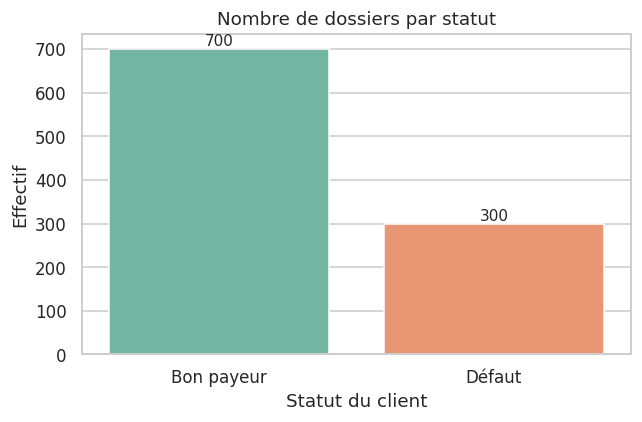

Taux de défaut global : 30.0%


In [7]:
# Diagramme en barres du nombre de clients par statut
fig, ax = plt.subplots(figsize=(6, 4))
ordre = ["Bon payeur", "Défaut"]
sns.countplot(data=df, x="statut", order=ordre, hue="statut", legend=False, ax=ax)
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height())}",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de dossiers par statut")
ax.set_xlabel("Statut du client")
ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()

print(f"Taux de défaut global : {df['defaut'].mean():.1%}")

**Lecture.** Les classes sont **déséquilibrées** : 30 % de défauts contre 70 % de bons payeurs. Ce n'est pas un déséquilibre extrême (comme en fraude), mais il impose une **validation stratifiée**, qui conserve cette proportion dans chaque pli, et le recours à des métriques adaptées : **PR-AUC** (qui se concentre sur la détection des défauts) en plus de la ROC-AUC. Une référence qui prédit toujours « bon payeur » aurait 70 % d'exactitude sans aucune utilité.

### 4.2 Distributions des variables numériques selon le statut

Un histogramme par statut montre si une variable aide à distinguer les défauts : plus les distributions sont séparées, plus la variable est informative.

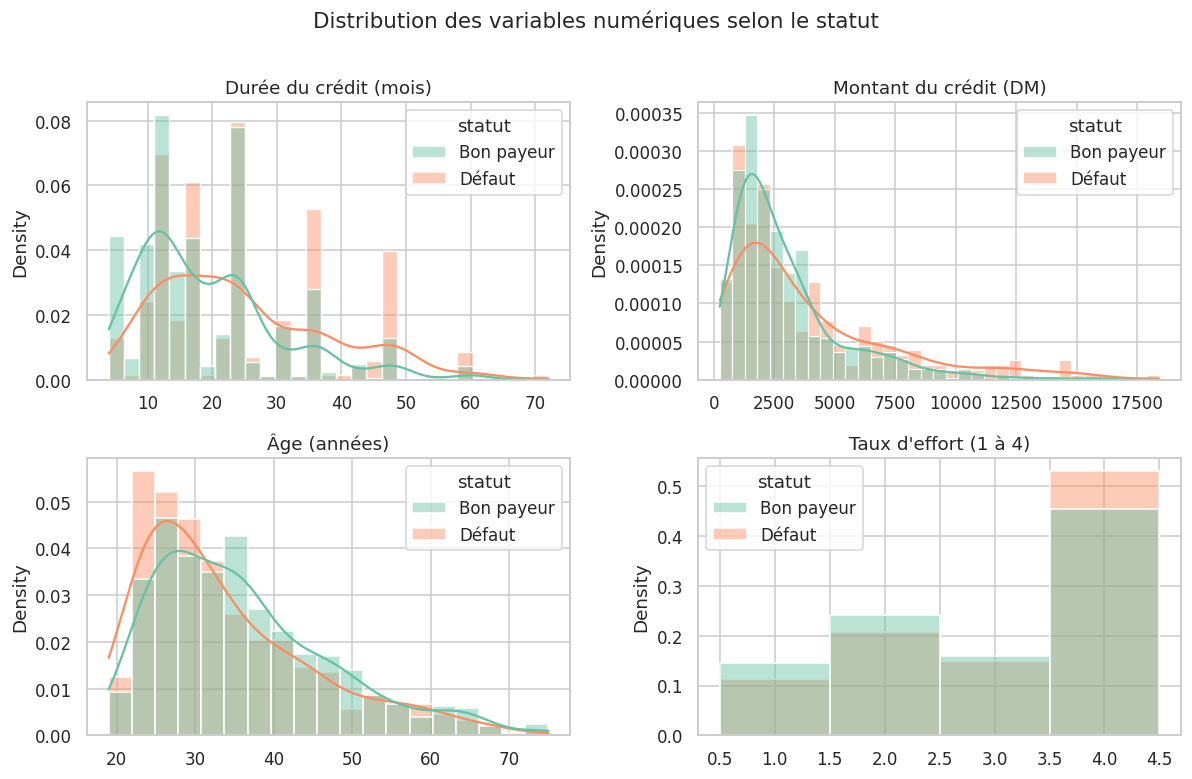

In [8]:
# Histogrammes superposés des variables numériques principales, par statut
principales = ["duree_mois", "montant", "age", "taux_effort"]
titres = ["Durée du crédit (mois)", "Montant du crédit (DM)", "Âge (années)", "Taux d'effort (1 à 4)"]
palette = {"Bon payeur": "#66c2a5", "Défaut": "#fc8d62"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, var, titre in zip(axes.ravel(), principales, titres):
    sns.histplot(data=df, x=var, hue="statut", kde=(var != "taux_effort"), stat="density",
                 common_norm=False, alpha=0.45, palette=palette, ax=ax,
                 discrete=(var == "taux_effort"))
    ax.set_title(titre)
    ax.set_xlabel("")
plt.suptitle("Distribution des variables numériques selon le statut", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Lecture.** Les défauts ont tendance à avoir des **crédits plus longs et plus élevés**, et à être un peu plus jeunes. Les distributions se chevauchent largement : aucune variable numérique ne sépare à elle seule les deux groupes. Il faudra donc combiner plusieurs variables, ce qui justifie un modèle multivarié.

### 4.3 Taux de défaut par segment

Pour un tableau de bord de risque, la lecture la plus parlante est le **taux de défaut observé par catégorie**. Chaque barre indique la part de mauvais payeurs dans le segment, et l'effectif est inscrit à côté : un taux calculé sur très peu de clients est peu fiable.

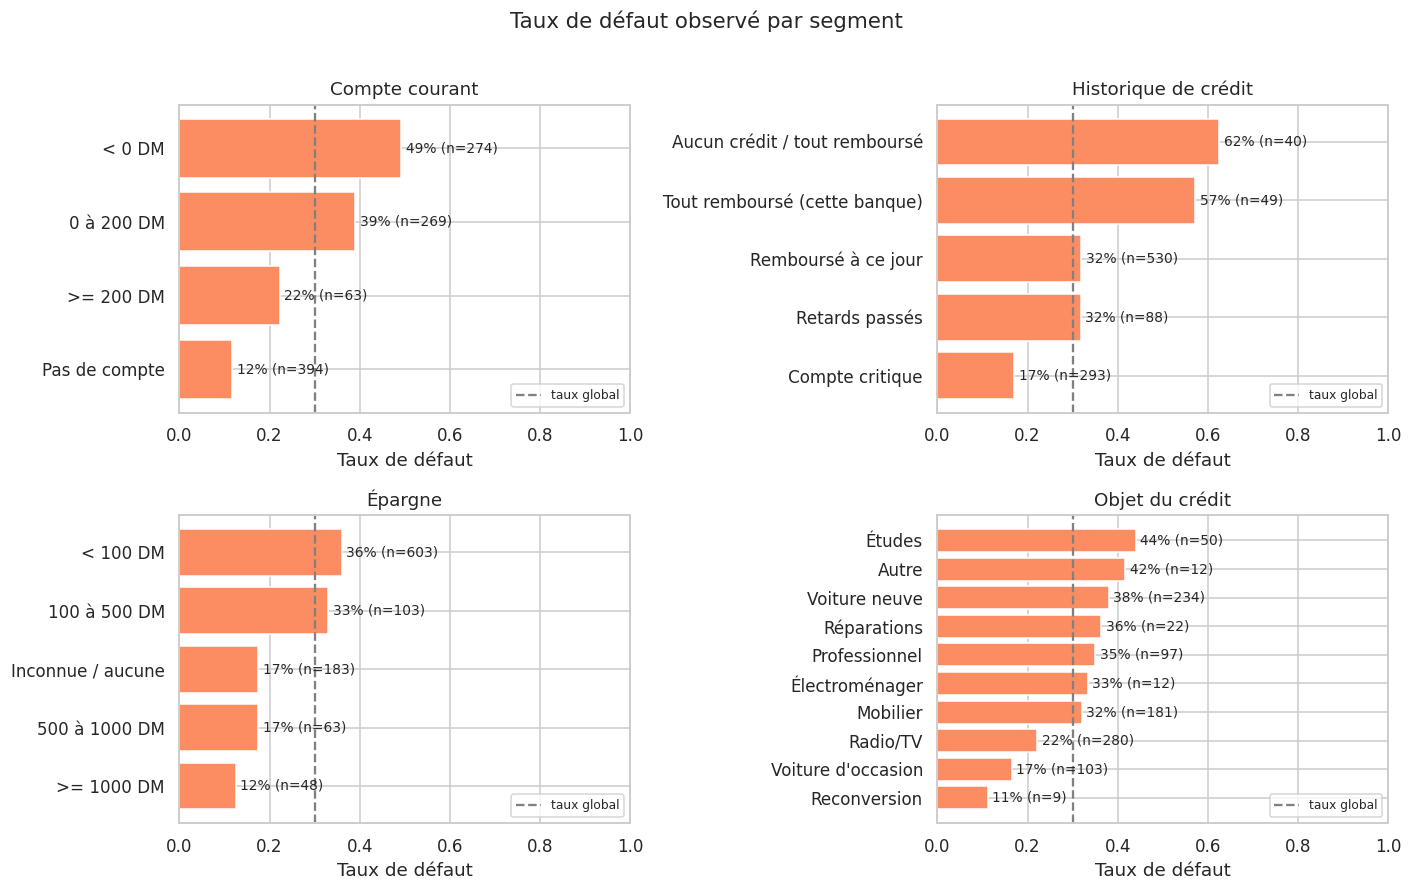

In [9]:
# Taux de défaut observé par catégorie, pour quatre variables clés
segments = [("compte_courant", "Compte courant"), ("historique_credit", "Historique de crédit"),
            ("epargne", "Épargne"), ("objet_credit", "Objet du crédit")]
taux_global = df["defaut"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (var, titre) in zip(axes.ravel(), segments):
    resume = df.groupby(var)["defaut"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(resume.index, resume["mean"], color=sns.color_palette("Set2")[1])
    ax.axvline(taux_global, color="grey", linestyle="--", label="taux global")
    for i, (taux, n) in enumerate(zip(resume["mean"], resume["size"])):
        ax.text(taux + 0.01, i, f"{taux:.0%} (n={n})", va="center", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_title(titre)
    ax.set_xlabel("Taux de défaut")
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle("Taux de défaut observé par segment", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Lecture.** Le **compte courant** est très discriminant : les clients sans compte ont un taux de défaut bien inférieur au taux global, tandis que ceux dont le compte est à découvert sont nettement au-dessus. L'**historique de crédit** va dans le sens attendu (un compte critique correspond à un risque plus faible que des retards passés, un résultat qui peut surprendre : ces clients ont déjà obtenu d'autres crédits et sont donc sélectionnés). Cela rappelle que ces taux décrivent des **associations**, pas des causes.

### 4.4 Corrélations

La matrice de corrélation indique les liens linéaires entre variables numériques et avec la cible. Deux variables très corrélées apportent une information redondante.

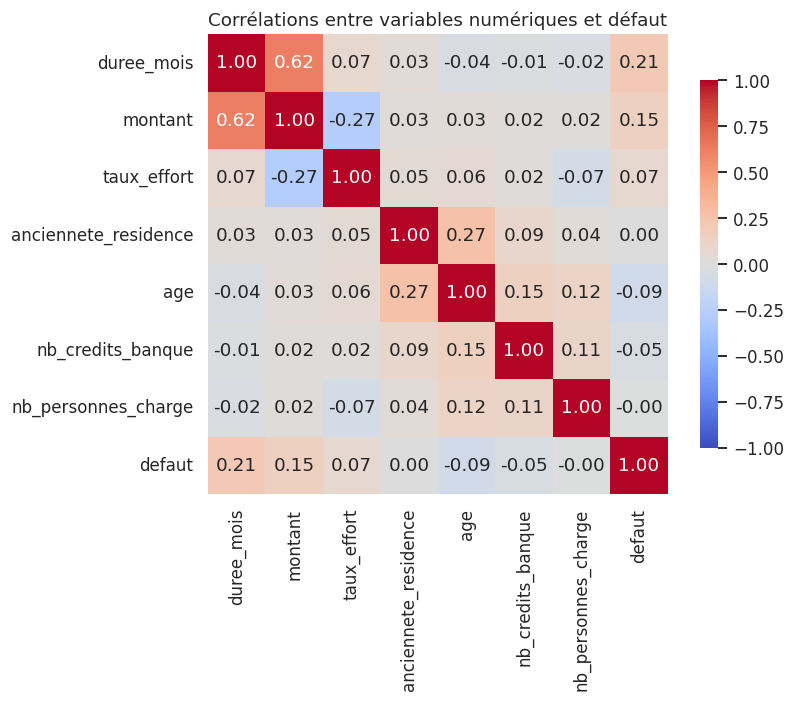

In [10]:
# Matrice de corrélation des variables numériques et de la cible
fig, ax = plt.subplots(figsize=(8, 6.5))
corr = df[variables_num + ["defaut"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques et défaut")
plt.tight_layout()
plt.show()

**Lecture.** La **durée** et le **montant** du crédit sont corrélés entre eux (un long crédit est souvent un gros crédit) et ce sont aussi les deux variables numériques les plus liées au défaut. Les corrélations avec la cible restent modestes : le signal est réparti sur de nombreuses variables, y compris catégorielles. Une régression logistique gagnera à être régularisée, ce que fait par défaut `scikit-learn`.

## 5. Préparation des données

Règles à respecter :

- **Ne jamais utiliser le jeu de test pendant la préparation.** Toute transformation (moyenne, écart-type, catégories) est apprise sur l'entraînement uniquement. C'est la principale source de **fuite de données** (*data leakage*).
- **Aucune valeur manquante** ici, donc pas d'imputation.
- **Encoder les variables catégorielles.** Un modèle ne lit pas le texte : les 13 variables catégorielles deviennent des colonnes 0/1 (*one-hot encoding*).
- **Standardiser les variables numériques** : $z = \dfrac{x - \bar x}{s}$, moyenne nulle et écart-type 1.
- **Découpage stratifié** : 75 % entraînement, 25 % test, en conservant la proportion de défauts.

Ces étapes sont regroupées dans un `Pipeline` : la même chaîne est alors appliquée à l'entraînement, à la validation et au test.

In [11]:
# 1) Séparation entrées / cible
X = df[variables_num + variables_cat]
y = df["defaut"]

# 2) Découpage stratifié : 75 % entraînement, 25 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Taux de défaut entraînement :", round(y_train.mean(), 3), "| test :", round(y_test.mean(), 3))

# 3) Prétraitement : standardisation des numériques, encodage des catégorielles
preprocesseur = ColumnTransformer([
    ("num", StandardScaler(), variables_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), variables_cat),
])

Entraînement : 750 | Test : 250
Taux de défaut entraînement : 0.3 | test : 0.3


## 6. Entraînement et comparaison de modèles

### 6.1 Principe de la comparaison

Nous comparons trois approches, du plus simple au plus complexe :

1. une **référence** (*baseline*) qui ignore les données et prédit toujours la proportion de défauts observée à l'entraînement ;
2. une **régression logistique**, modèle linéaire standard en scoring de crédit, facile à expliquer à un comité de risque ;
3. une **forêt aléatoire**, ensemble d'arbres capable de capturer des interactions non linéaires.

Pour comparer équitablement, on utilise une **validation croisée stratifiée à 5 plis sur l'ensemble d'entraînement**. Le jeu de test reste de côté jusqu'à l'évaluation finale. Trois métriques sont suivies :

- **ROC-AUC** : probabilité qu'un défaut reçoive un score plus élevé qu'un bon payeur pris au hasard (0,5 = hasard, 1 = parfait) ;
- **PR-AUC** (précision moyenne) : qualité de la détection des défauts, la référence valant environ la proportion de défauts (0,30) ;
- **Score de Brier** : erreur quadratique moyenne des probabilités (plus il est bas, mieux c'est).

In [12]:
# Modèles candidats, chacun précédé du même prétraitement
modeles = {
    "Référence (proportion de défauts)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=2000),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              random_state=42, n_jobs=-1),
}

pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)])
             for nom, m in modeles.items()}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}

resultats = []
for nom, pipe in pipelines.items():
    cv = cross_validate(pipe, X_train, y_train, cv=validation, scoring=scoring)
    resultats.append({
        "Modèle": nom,
        "ROC-AUC": cv["test_roc_auc"].mean(), "ROC-AUC (écart-type)": cv["test_roc_auc"].std(),
        "PR-AUC": cv["test_pr_auc"].mean(), "PR-AUC (écart-type)": cv["test_pr_auc"].std(),
        "Brier": -cv["test_brier"].mean(),
    })

tableau = pd.DataFrame(resultats).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
tableau.round(3)

,Modèle,ROC-AUC,ROC-AUC (écart-type),PR-AUC,PR-AUC (écart-type),Brier
0,Forêt aléatoire,0.784,0.012,0.592,0.029,0.170
1,Régression logistique,0.765,0.036,0.592,0.039,0.173
2,Référence (proportion de défauts),0.500,0.000,0.300,0.000,0.210


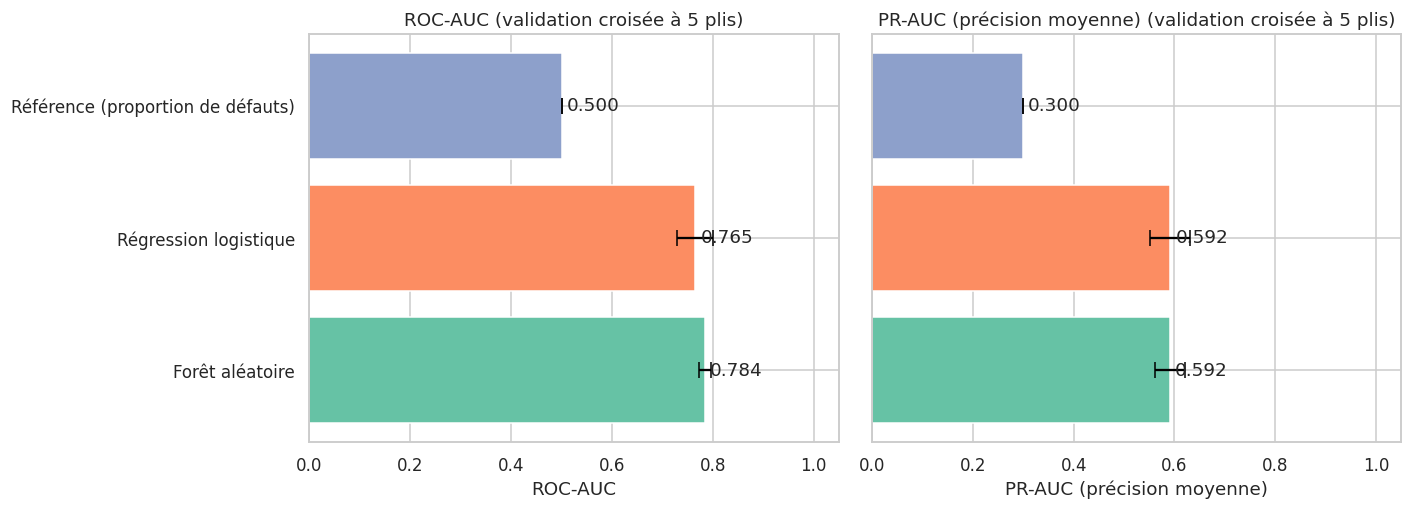

In [13]:
# Graphique : ROC-AUC et PR-AUC en validation croisée, avec barres d'erreur
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
couleurs = sns.color_palette("Set2", len(tableau))
for ax, metrique, titre in zip(axes, ["ROC-AUC", "PR-AUC"], ["ROC-AUC", "PR-AUC (précision moyenne)"]):
    ax.barh(tableau["Modèle"], tableau[metrique], xerr=tableau[f"{metrique} (écart-type)"],
            capsize=5, color=couleurs)
    ax.set_xlim(0, 1.05)
    ax.invert_yaxis()
    for i, val in enumerate(tableau[metrique]):
        ax.text(val + 0.01, i, f"{val:.3f}", va="center")
    ax.set_title(f"{titre} (validation croisée à 5 plis)")
    ax.set_xlabel(titre)
plt.tight_layout()
plt.show()

**Lecture.** La référence donne une ROC-AUC de 0,5 (aucune capacité de tri) et une PR-AUC proche de 0,30, la proportion de défauts : c'est le niveau à battre. Les deux modèles appris font nettement mieux. Comparez leurs écarts-types : un modèle un peu meilleur en moyenne mais très variable d'un pli à l'autre est moins fiable. Avec seulement 750 dossiers d'entraînement, l'écart entre régression logistique et forêt aléatoire peut rester dans le bruit d'estimation, ce qui est un résultat classique sur ce jeu de données.

## 7. Calibration des probabilités

### 7.1 Pourquoi calibrer ?

Un modèle est **calibré** si, parmi les clients auxquels il attribue une PD de 20 %, environ 20 % font réellement défaut. Cette propriété est indispensable pour le calcul des provisions, de la tarification et des seuils de décision. Or :

- la **régression logistique** est en général assez bien calibrée par construction ;
- la **forêt aléatoire** moyenne les votes d'arbres et produit souvent des probabilités trop « timides » (peu de valeurs proches de 0 ou de 1).

On peut corriger cela avec `CalibratedClassifierCV`, qui apprend une transformation des scores par validation croisée :

- **Platt** (`sigmoid`) : ajuste une courbe logistique, adaptée aux petits échantillons ;
- **isotonique** : ajuste une fonction en escalier croissante, plus flexible mais exposée au surapprentissage quand les données sont peu nombreuses.

Pour ne pas contaminer le jeu de test, la comparaison se fait sur des **prédictions hors échantillon** (`cross_val_predict`) calculées sur l'entraînement.

In [14]:
# Candidats : modèles bruts et versions calibrées de la forêt aléatoire
pipe_lr = Pipeline([("prep", preprocesseur), ("modele", LogisticRegression(max_iter=2000))])
pipe_rf = Pipeline([("prep", preprocesseur),
                    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                      random_state=42, n_jobs=-1))])

candidats = {
    "Régression logistique": pipe_lr,
    "Forêt aléatoire (brute)": pipe_rf,
    "Forêt aléatoire + Platt": CalibratedClassifierCV(pipe_rf, method="sigmoid", cv=5),
    "Forêt aléatoire + isotonique": CalibratedClassifierCV(pipe_rf, method="isotonic", cv=5),
}

# Probabilités de défaut hors échantillon sur l'entraînement
proba_oof = {nom: cross_val_predict(m, X_train, y_train, cv=validation, method="predict_proba")[:, 1]
             for nom, m in candidats.items()}

calib = pd.DataFrame({
    "Modèle": list(proba_oof.keys()),
    "ROC-AUC": [roc_auc_score(y_train, p) for p in proba_oof.values()],
    "PR-AUC": [average_precision_score(y_train, p) for p in proba_oof.values()],
    "Brier": [brier_score_loss(y_train, p) for p in proba_oof.values()],
}).sort_values("Brier").reset_index(drop=True)
calib.round(3)

,Modèle,ROC-AUC,PR-AUC,Brier
0,Forêt aléatoire + Platt,0.790,0.580,0.165
1,Forêt aléatoire + isotonique,0.790,0.588,0.166
2,Forêt aléatoire (brute),0.786,0.579,0.170
3,Régression logistique,0.766,0.587,0.173


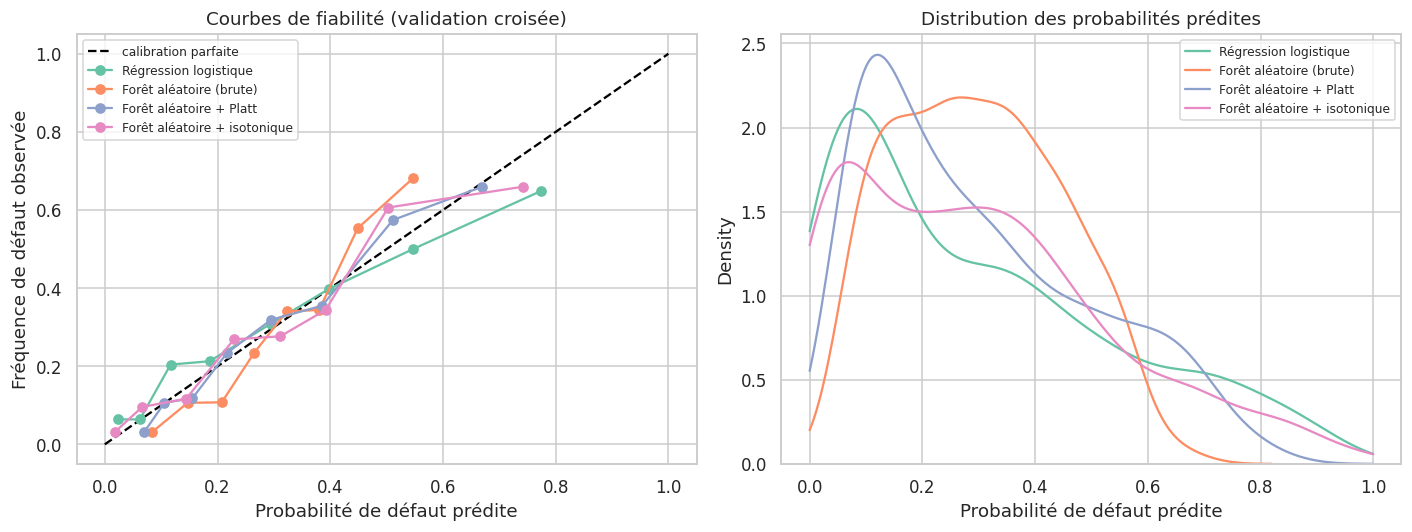

In [15]:
# Courbes de fiabilité (reliability curves) hors échantillon
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot([0, 1], [0, 1], "k--", label="calibration parfaite")
for nom, p in proba_oof.items():
    frac_reelle, proba_moy = calibration_curve(y_train, p, n_bins=8, strategy="quantile")
    axes[0].plot(proba_moy, frac_reelle, "o-", label=nom)
axes[0].set_xlabel("Probabilité de défaut prédite")
axes[0].set_ylabel("Fréquence de défaut observée")
axes[0].set_title("Courbes de fiabilité (validation croisée)")
axes[0].legend(fontsize=8)

for nom, p in proba_oof.items():
    sns.kdeplot(p, ax=axes[1], label=nom, clip=(0, 1))
axes[1].set_xlabel("Probabilité de défaut prédite")
axes[1].set_title("Distribution des probabilités prédites")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lecture.** Plus une courbe colle à la diagonale, mieux le modèle est calibré. Une courbe qui reste au-dessus de la diagonale à gauche et en dessous à droite signale des probabilités trop resserrées autour de la moyenne, ce qui est typique d'une forêt aléatoire brute. Le **score de Brier** résume cette qualité en un chiffre : il combine calibration et pouvoir de tri. La ROC-AUC, elle, ne change presque pas avec la calibration, puisque celle-ci conserve l'ordre des scores : **calibrer améliore la fiabilité des probabilités, pas le classement des clients**.

Nous retenons automatiquement le candidat au meilleur score de Brier hors échantillon.

In [16]:
# Sélection du modèle final : meilleur score de Brier hors échantillon
nom_final = calib.iloc[0]["Modèle"]
modele_final = candidats[nom_final].fit(X_train, y_train)
print("Modèle retenu :", nom_final)

Modèle retenu : Forêt aléatoire + Platt


## 8. Décision d'octroi : choix du seuil avec la matrice de coûts

Un modèle fournit une probabilité ; la banque doit décider. La règle est : **refuser le crédit si PD ≥ seuil**. La documentation du jeu de données donne les coûts :

| | Prédit « bon » (crédit accordé) | Prédit « défaut » (crédit refusé) |
|---|---|---|
| **Réellement bon** | 0 | 1 (manque à gagner) |
| **Réellement défaut** | 5 (perte en capital) | 0 |

Si les probabilités sont bien calibrées, le seuil théorique qui minimise le coût attendu est $\dfrac{c_{\text{FP}}}{c_{\text{FP}} + c_{\text{FN}}} = \dfrac{1}{1+5} \approx 0{,}167$. Autrement dit, la banque doit refuser dès que le risque dépasse environ 17 %, bien en dessous de 50 %, car une erreur sur un mauvais payeur coûte cinq fois plus cher.

Nous cherchons le seuil sur les prédictions **hors échantillon de l'entraînement**, jamais sur le test.

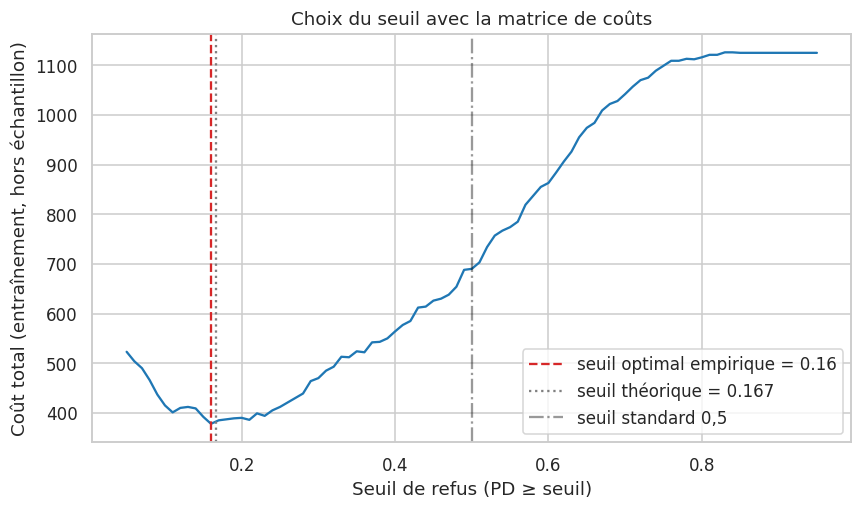

Coût au seuil 0,5     : 690
Coût au seuil optimal : 378


In [17]:
# Coût total en fonction du seuil, calculé hors échantillon sur l'entraînement
COUT_FN = 5   # accorder un crédit à un mauvais payeur
COUT_FP = 1   # refuser un bon payeur

def cout_total(y_vrai, proba, seuil):
    refus = proba >= seuil
    fn = np.sum((~refus) & (y_vrai == 1))
    fp = np.sum(refus & (y_vrai == 0))
    return COUT_FN * fn + COUT_FP * fp

p_oof = proba_oof[nom_final]
seuils = np.linspace(0.05, 0.95, 91)
couts = np.array([cout_total(y_train.values, p_oof, s) for s in seuils])
seuil_opt = seuils[couts.argmin()]
seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(seuils, couts, color="tab:blue")
ax.axvline(seuil_opt, color="tab:red", linestyle="--", label=f"seuil optimal empirique = {seuil_opt:.2f}")
ax.axvline(seuil_theorique, color="grey", linestyle=":", label=f"seuil théorique = {seuil_theorique:.3f}")
ax.axvline(0.5, color="black", linestyle="-.", alpha=0.4, label="seuil standard 0,5")
ax.set_xlabel("Seuil de refus (PD ≥ seuil)")
ax.set_ylabel("Coût total (entraînement, hors échantillon)")
ax.set_title("Choix du seuil avec la matrice de coûts")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Coût au seuil 0,5     : {cout_total(y_train.values, p_oof, 0.5):.0f}")
print(f"Coût au seuil optimal : {cout_total(y_train.values, p_oof, seuil_opt):.0f}")
SEUIL = seuil_opt

**Lecture.** Le seuil standard de 0,5 est **inadapté** quand les erreurs n'ont pas le même coût : il laisse passer trop de mauvais payeurs. Le seuil optimal est nettement plus bas, proche de la valeur théorique. La courbe de coût est assez plate autour de son minimum : le seuil exact importe moins que le fait d'être dans la bonne zone. Cette valeur est une estimation bruitée (750 dossiers) ; en pratique, on la réexaminerait régulièrement.

## 9. Évaluation finale sur le jeu de test

Le modèle retenu, déjà entraîné sur tout l'ensemble d'entraînement, est évalué **une seule fois** sur le jeu de test, avec le seuil fixé à l'étape précédente. Ce score estime la performance sur de nouveaux demandeurs.

In [18]:
# Évaluation sur le jeu de test
p_test = modele_final.predict_proba(X_test)[:, 1]
refus_test = (p_test >= SEUIL).astype(int)

print("Modèle retenu :", nom_final, "| seuil de refus :", round(SEUIL, 2))
print(f"ROC-AUC (test)        : {roc_auc_score(y_test, p_test):.3f}")
print(f"PR-AUC (test)         : {average_precision_score(y_test, p_test):.3f}   (référence : {y_test.mean():.2f})")
print(f"Score de Brier (test) : {brier_score_loss(y_test, p_test):.3f}")
print(f"Coût total (test)     : {cout_total(y_test.values, p_test, SEUIL):.0f}")
print(f"Coût si tout accordé  : {COUT_FN * int(y_test.sum())}")
print()
print(classification_report(y_test, refus_test, target_names=["Bon payeur", "Défaut"]))

Modèle retenu : Forêt aléatoire + Platt | seuil de refus : 0.16
ROC-AUC (test)        : 0.802
PR-AUC (test)         : 0.626   (référence : 0.30)
Score de Brier (test) : 0.160
Coût total (test)     : 127
Coût si tout accordé  : 375

              precision    recall  f1-score   support

  Bon payeur       0.92      0.47      0.63       175
      Défaut       0.42      0.91      0.58        75

    accuracy                           0.60       250
   macro avg       0.67      0.69      0.60       250
weighted avg       0.77      0.60      0.61       250



### 9.1 Matrice de confusion, courbes ROC et précision-rappel

La matrice de confusion croise le statut réel et la décision. Pour une banque, deux cases comptent : les **défauts acceptés** (faux négatifs, coût 5) et les **bons clients refusés** (faux positifs, coût 1). Les courbes ROC et précision-rappel résument la performance pour tous les seuils possibles.

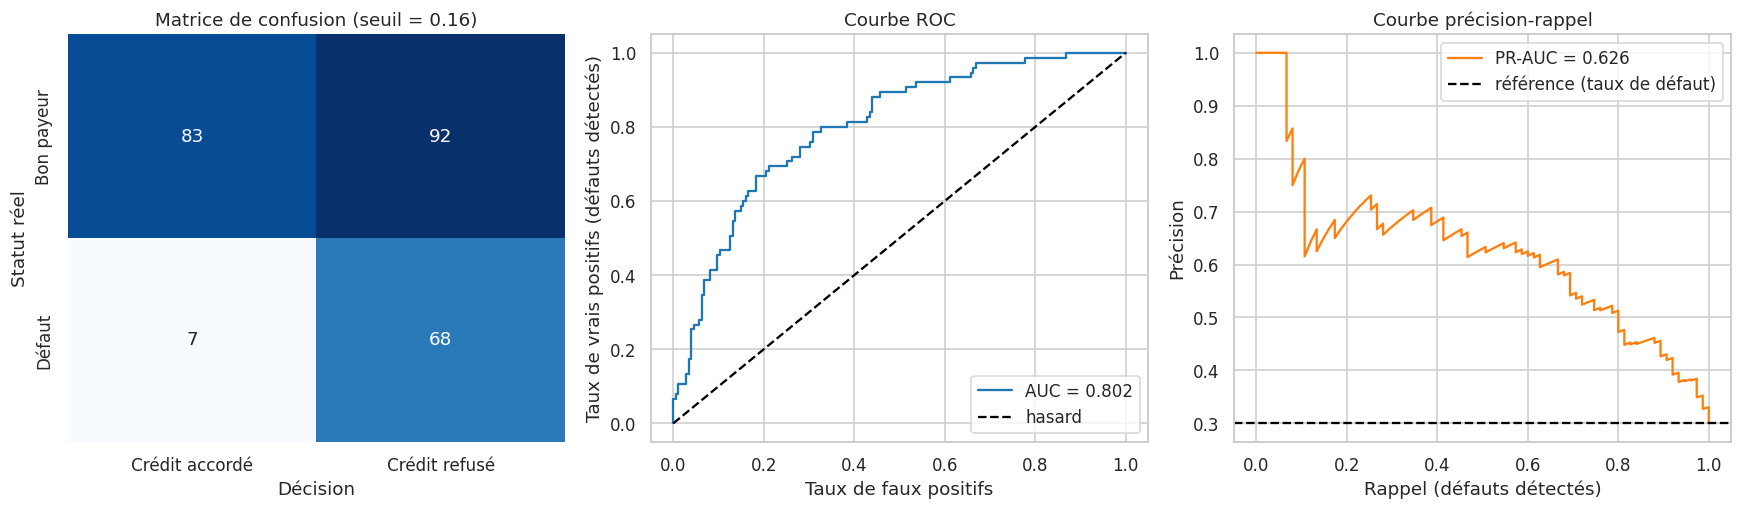

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Matrice de confusion à gauche
cm = confusion_matrix(y_test, refus_test, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Crédit accordé", "Crédit refusé"], yticklabels=["Bon payeur", "Défaut"])
axes[0].set_title(f"Matrice de confusion (seuil = {SEUIL:.2f})")
axes[0].set_xlabel("Décision")
axes[0].set_ylabel("Statut réel")

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, color="tab:blue", label=f"AUC = {roc_auc_score(y_test, p_test):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", label="hasard")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs (défauts détectés)")
axes[1].set_title("Courbe ROC")
axes[1].legend(loc="lower right")

# Courbe précision-rappel
prec, rapp, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rapp, prec, color="tab:orange", label=f"PR-AUC = {average_precision_score(y_test, p_test):.3f}")
axes[2].axhline(y_test.mean(), color="k", linestyle="--", label="référence (taux de défaut)")
axes[2].set_xlabel("Rappel (défauts détectés)")
axes[2].set_ylabel("Précision")
axes[2].set_title("Courbe précision-rappel")
axes[2].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Lecture.** Avec un seuil bas, le modèle **détecte la majorité des défauts** (rappel élevé) au prix de nombreux refus de bons clients (précision modeste sur la classe « défaut »). C'est le compromis voulu : refuser un bon client coûte 1, accepter un défaut coûte 5. Comparez le coût obtenu à celui d'une banque qui accorderait tous les crédits : la différence mesure la valeur apportée par le modèle. Sur 250 dossiers de test, seulement environ 75 défauts : les chiffres bougeraient avec un autre découpage, il faut les lire avec prudence.

### 9.2 Fiabilité des probabilités sur le test

Nous vérifions enfin que la calibration observée en validation croisée se retrouve sur des données jamais vues.

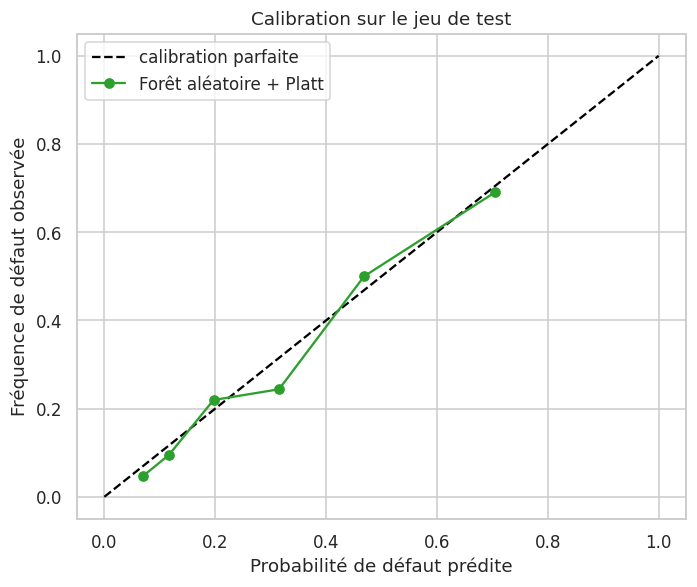

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
frac_reelle, proba_moy = calibration_curve(y_test, p_test, n_bins=6, strategy="quantile")
ax.plot([0, 1], [0, 1], "k--", label="calibration parfaite")
ax.plot(proba_moy, frac_reelle, "o-", color="tab:green", label=nom_final)
ax.set_xlabel("Probabilité de défaut prédite")
ax.set_ylabel("Fréquence de défaut observée")
ax.set_title("Calibration sur le jeu de test")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** Sur un échantillon de test aussi petit, les points sont bruités : un écart modéré avec la diagonale n'est pas forcément un défaut du modèle. On cherche surtout l'absence d'écart systématique (par exemple un modèle qui sous-estimerait le risque sur toute la plage de probabilités, ce qui serait dangereux pour une banque).

## 10. Interprétation du modèle

Un modèle de crédit doit pouvoir être **expliqué** : au régulateur, au comité de risque et au client refusé. Nous utilisons deux outils complémentaires.

### 10.1 Coefficients de la régression logistique

Dans une régression logistique, chaque coefficient mesure l'effet d'une variable sur le logarithme du rapport de cotes de défaut. Un coefficient positif augmente le risque, un coefficient négatif le diminue. Les variables numériques étant standardisées, leurs coefficients sont comparables entre eux.

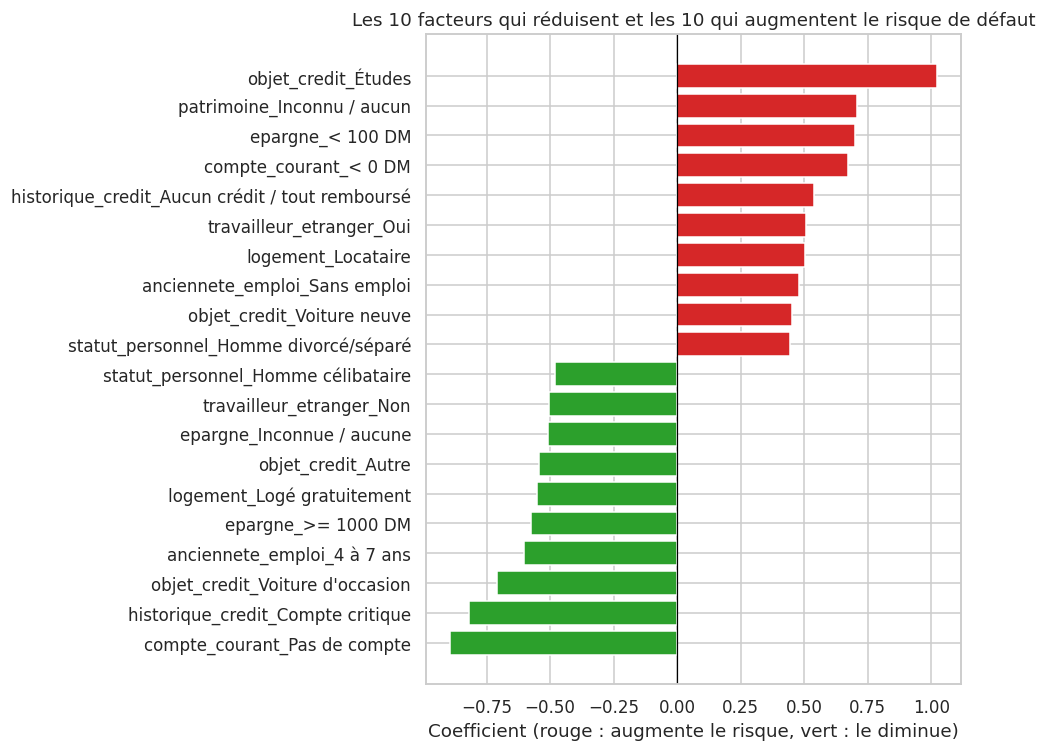

In [21]:
# Coefficients de la régression logistique ajustée sur l'entraînement
lr = Pipeline([("prep", preprocesseur), ("modele", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
noms = lr.named_steps["prep"].get_feature_names_out()
noms = [n.replace("num__", "").replace("cat__", "") for n in noms]
coefs = pd.Series(lr.named_steps["modele"].coef_[0], index=noms).sort_values()

extremes = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7))
couleurs = ["tab:green" if v < 0 else "tab:red" for v in extremes]
ax.barh(extremes.index, extremes.values, color=couleurs)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (rouge : augmente le risque, vert : le diminue)")
ax.set_title("Les 10 facteurs qui réduisent et les 10 qui augmentent le risque de défaut")
plt.tight_layout()
plt.show()

**Lecture.** Les facteurs protecteurs les plus marqués concernent la situation du compte courant et de l'épargne ; les facteurs aggravants incluent un compte à découvert, la durée et le montant du crédit. Attention : une variable catégorielle encodée en one-hot est comparée à l'ensemble des autres modalités, et les modalités rares ont des coefficients instables. Il s'agit d'**associations statistiques**, pas de relations de cause à effet.

### 10.2 Importance par permutation

L'importance par permutation mesure la **baisse de ROC-AUC** quand on mélange aléatoirement les valeurs d'une variable. Elle s'applique à n'importe quel modèle, y compris le modèle final retenu, et travaille sur les variables d'origine (non encodées).

In [ ]:
# Importance par permutation du modèle final, sur le jeu de test
perm = permutation_importance(modele_final, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=42, n_jobs=-1)
importances = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(12)
erreurs = pd.Series(perm.importances_std, index=X_test.columns)[importances.index]

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(importances.index, importances.values, xerr=erreurs.values, capsize=3, color="teal")
ax.set_xlabel("Baisse moyenne de la ROC-AUC après permutation")
ax.set_title(f"Importance des variables par permutation : {nom_final}")
plt.tight_layout()
plt.show()

**Lecture.** Les variables en haut du graphique sont celles dont la perte dégrade le plus le classement des clients. Les barres d'erreur rappellent que, sur 250 dossiers, l'importance des variables secondaires est incertaine : une variable dont la barre touche zéro ne doit pas être interprétée. Cette importance dépend du modèle et peut être diluée entre variables corrélées (durée et montant ici).

## 11. Le tableau de bord de risque

### 11.1 Grille de notation : classes de risque

Les banques regroupent les clients en **classes de risque** (notes de A à E) pour piloter le portefeuille. Nous construisons cinq classes à partir des quintiles des PD **hors échantillon de l'entraînement** : les bornes sont fixées sans regarder le test, puis appliquées aux nouveaux clients. Pour chaque classe, on compare la **PD moyenne prédite** au **taux de défaut réellement observé** : s'ils sont proches, la grille est fiable.

In [ ]:
# Bornes des classes de risque : quintiles des PD hors échantillon (entraînement)
bornes = np.quantile(p_oof, [0.2, 0.4, 0.6, 0.8])
bornes_completes = np.concatenate([[-np.inf], bornes, [np.inf]])
notes = ["A (très faible)", "B (faible)", "C (moyen)", "D (élevé)", "E (très élevé)"]

def attribuer_classe(proba):
    return pd.cut(proba, bins=bornes_completes, labels=notes)

test_resultats = X_test.copy()
test_resultats["pd_predite"] = p_test
test_resultats["defaut"] = y_test.values
test_resultats["classe_risque"] = attribuer_classe(p_test)
test_resultats["refus"] = refus_test

grille = (test_resultats.groupby("classe_risque", observed=True)
          .agg(effectif=("defaut", "size"),
               pd_moyenne_predite=("pd_predite", "mean"),
               taux_defaut_observe=("defaut", "mean"),
               montant_moyen=("montant", "mean"),
               taux_refus=("refus", "mean")))
print("Bornes des classes (PD) :", np.round(bornes, 3))
grille.round(3)

In [ ]:
# Prédit vs observé par classe de risque
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(grille))
largeur = 0.38
ax.bar(x - largeur / 2, grille["pd_moyenne_predite"], largeur, label="PD moyenne prédite", color="#8da0cb")
ax.bar(x + largeur / 2, grille["taux_defaut_observe"], largeur, label="Taux de défaut observé", color="#fc8d62")
for i, (a, b, n) in enumerate(zip(grille["pd_moyenne_predite"], grille["taux_defaut_observe"], grille["effectif"])):
    ax.text(i - largeur / 2, a + 0.01, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i + largeur / 2, b + 0.01, f"{b:.0%}", ha="center", fontsize=9)
    ax.text(i, -0.07, f"n={n}", ha="center", fontsize=8, color="grey")
ax.set_xticks(x)
ax.set_xticklabels(grille.index, rotation=0, fontsize=9)
ax.set_ylabel("Probabilité / taux de défaut")
ax.set_title("Classes de risque : PD prédite et taux de défaut observé (test)")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** Le taux de défaut observé doit **croître de A à E** : c'est la propriété fondamentale d'une grille de notation (monotonie). La classe E concentre une grande part des défauts, la classe A en contient très peu. Chaque classe ne compte qu'une cinquantaine de clients dans le test : un léger écart entre PD prédite et taux observé reste dans la marge d'échantillonnage.

### 11.2 Vue synthétique

Nous rassemblons les indicateurs clés dans une seule figure, comme un tableau de bord destiné à un comité de risque.

In [ ]:
# Tableau de bord synthétique
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.3)

# (1) Indicateurs clés
ax = fig.add_subplot(gs[0, 0])
ax.axis("off")
cout_modele = cout_total(y_test.values, p_test, SEUIL)
cout_tout_accorde = COUT_FN * int(y_test.sum())
economie = 1 - cout_modele / cout_tout_accorde
indicateurs = [
    ("Modèle retenu", nom_final),
    ("Dossiers (test)", f"{len(y_test)}"),
    ("Taux de défaut observé", f"{y_test.mean():.1%}"),
    ("ROC-AUC", f"{roc_auc_score(y_test, p_test):.3f}"),
    ("PR-AUC", f"{average_precision_score(y_test, p_test):.3f}"),
    ("Score de Brier", f"{brier_score_loss(y_test, p_test):.3f}"),
    ("Seuil de refus", f"PD ≥ {SEUIL:.2f}"),
    ("Taux de refus", f"{refus_test.mean():.1%}"),
    ("Coût vs tout accorder", f"{-economie:+.0%}"),
]
ax.set_title("Indicateurs clés", loc="left", fontweight="bold")
for i, (nom, val) in enumerate(indicateurs):
    ax.text(0.0, 0.92 - i * 0.105, nom, fontsize=11, color="grey", transform=ax.transAxes)
    ax.text(1.0, 0.92 - i * 0.105, val, fontsize=11, fontweight="bold", ha="right", transform=ax.transAxes)

# (2) Distribution des scores par statut réel
ax = fig.add_subplot(gs[0, 1])
sns.histplot(x=p_test, hue=y_test.map({0: "Bon payeur", 1: "Défaut"}).values, bins=20,
             stat="density", common_norm=False, alpha=0.5, palette=palette, ax=ax)
ax.axvline(SEUIL, color="red", linestyle="--")
ax.set_title("Scores de risque selon le statut réel")
ax.set_xlabel("PD prédite")

# (3) Courbe ROC
ax = fig.add_subplot(gs[0, 2])
ax.plot(fpr, tpr, color="tab:blue", label=f"AUC = {roc_auc_score(y_test, p_test):.3f}")
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Courbe ROC")
ax.set_xlabel("Faux positifs")
ax.set_ylabel("Défauts détectés")
ax.legend(loc="lower right")

# (4) Défauts par classe de risque
ax = fig.add_subplot(gs[1, 0])
ax.bar(grille.index.astype(str), grille["taux_defaut_observe"], color=sns.color_palette("RdYlGn_r", 5))
ax.set_title("Taux de défaut par classe de risque")
ax.set_ylabel("Taux de défaut observé")
ax.tick_params(axis="x", rotation=30, labelsize=8)

# (5) Calibration
ax = fig.add_subplot(gs[1, 1])
ax.plot([0, 1], [0, 1], "k--")
ax.plot(proba_moy, frac_reelle, "o-", color="tab:green")
ax.set_title("Calibration (test)")
ax.set_xlabel("PD prédite")
ax.set_ylabel("Fréquence observée")

# (6) Matrice de confusion
ax = fig.add_subplot(gs[1, 2])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Accordé", "Refusé"], yticklabels=["Bon", "Défaut"])
ax.set_title("Décisions vs statut réel")

plt.suptitle("Tableau de bord du risque de crédit : German Credit", fontsize=16, fontweight="bold", y=0.98)
plt.show()

**Lecture.** Cette vue regroupe ce qu'un décideur veut voir : la performance (ROC-AUC, PR-AUC), la fiabilité des probabilités (Brier, calibration), l'effet de la décision (taux de refus, coût par rapport à la politique « tout accorder ») et la structure du portefeuille par classe de risque. Le tableau de bord ne remplace pas une validation indépendante : il résume un seul découpage sur un petit échantillon.

## 12. Limites : fuite de données, biais et représentativité

Un modèle de crédit n'est utilisable que si ses limites sont connues. Voici les principales, à discuter dans votre rapport.

- **Fuite de données (*leakage*)** : toutes les transformations sont apprises dans un `Pipeline` sur l'entraînement, le seuil et les bornes de classes sont fixés hors échantillon, et le test n'est utilisé qu'une fois. Un prétraitement fait avant le découpage fausserait les scores.
- **Taille d'échantillon** : 1 000 dossiers seulement, dont 300 défauts. Les estimations (seuil, taux par classe, importances) sont bruitées.
- **Déséquilibre** : 30 % de défauts. D'où l'usage de la validation stratifiée, de la PR-AUC et d'une matrice de coûts.
- **Dérive temporelle** : les données datent des années 1990 et décrivent des clients allemands, en deutsche mark. Les comportements, les produits et les taux ont changé. Un tel modèle ne pourrait pas être déployé tel quel et devrait être revalidé sur des données récentes.
- **Représentativité et biais de sélection** : on n'observe que les clients **à qui la banque a accordé un crédit**. Les demandeurs refusés sont absents, ce qui biaise l'apprentissage (c'est le problème de l'*inférence des refusés*).
- **Équité** : des variables comme le sexe, l'âge ou le statut de travailleur étranger sont sensibles. Leur usage est encadré, voire interdit, dans de nombreuses juridictions. Il faut mesurer les écarts de décision entre groupes.

Le contrôle d'équité ci-dessous est volontairement simple : il compare le taux de refus et le taux de défaut observé selon l'âge et le statut personnel.

In [ ]:
# Audit simple d'équité : taux de refus et taux de défaut observé par groupe (jeu de test)
test_resultats["tranche_age"] = pd.cut(test_resultats["age"], bins=[0, 25, 35, 50, 120],
                                       labels=["< 25 ans", "25-34 ans", "35-49 ans", ">= 50 ans"])

for groupe in ["tranche_age", "statut_personnel"]:
    audit = (test_resultats.groupby(groupe, observed=True)
             .agg(effectif=("defaut", "size"),
                  taux_refus=("refus", "mean"),
                  taux_defaut_observe=("defaut", "mean")))
    print(f"--- Par {groupe} ---")
    display(audit.round(3))

**Lecture.** Si le taux de refus d'un groupe dépasse nettement son taux de défaut observé, le modèle pénalise ce groupe au-delà de son risque réel. Mais les effectifs de certains groupes sont très faibles dans le test (quelques dizaines de dossiers, parfois moins) : aucune conclusion ferme ne peut être tirée de ce tableau. Dans un vrai projet, on l'établirait sur un échantillon bien plus grand, avec des intervalles de confiance.

## 13. Scorer un nouveau dossier

Une fois le modèle validé, il sert à scorer un nouveau demandeur. Le pipeline applique automatiquement la même standardisation et le même encodage qu'à l'entraînement, puis on lit la PD, la classe de risque et la décision.

In [ ]:
# Nouveau dossier fictif
nouveau = pd.DataFrame([{
    "duree_mois": 24, "montant": 4500, "taux_effort": 3, "anciennete_residence": 2,
    "age": 31, "nb_credits_banque": 1, "nb_personnes_charge": 1,
    "compte_courant": "0 à 200 DM", "historique_credit": "Remboursé à ce jour",
    "objet_credit": "Voiture neuve", "epargne": "< 100 DM", "anciennete_emploi": "1 à 4 ans",
    "statut_personnel": "Homme célibataire", "autres_debiteurs": "Aucun",
    "patrimoine": "Voiture / autre", "autres_credits": "Aucun", "logement": "Locataire",
    "emploi": "Qualifié", "telephone": "Oui", "travailleur_etranger": "Non",
}])[variables_num + variables_cat]

pd_nouveau = modele_final.predict_proba(nouveau)[0, 1]
print(f"Probabilité de défaut estimée : {pd_nouveau:.1%}")
print("Classe de risque              :", attribuer_classe(np.array([pd_nouveau]))[0])
print("Décision                      :", "REFUS" if pd_nouveau >= SEUIL else "ACCORD",
      f"(seuil = {SEUIL:.2f})")

## 14. Synthèse et questions

### Ce qu'il faut retenir

1. **Type d'apprentissage** : supervisé, classification binaire (défaut / bon payeur), avec un volet de calibration des probabilités.
2. **Démarche** : explorer, prétraiter dans un pipeline, comparer à une référence, valider par validation croisée stratifiée, évaluer une seule fois sur le test.
3. **Métriques** : l'exactitude est trompeuse avec des classes déséquilibrées. On suit la ROC-AUC, la PR-AUC et le score de Brier.
4. **Calibration** : elle rend les probabilités fiables sans changer le classement des clients. C'est ce qui permet de fixer un seuil à partir de coûts.
5. **Décision** : le seuil de refus se déduit de la matrice de coûts (environ 17 % en théorie), pas de la valeur 0,5.
6. **Limites** : petit échantillon, données anciennes, biais de sélection, équité. Ce modèle est pédagogique et **ne doit pas servir à de vraies décisions de crédit**.

### Questions

1. Pourquoi une forêt aléatoire brute est-elle souvent mal calibrée alors que sa ROC-AUC est bonne ? Que change `CalibratedClassifierCV` et que ne change-t-il pas ?
2. Modifiez les coûts (par exemple `COUT_FN = 10` puis `COUT_FN = 2`). Comment évoluent le seuil optimal, le taux de refus et le coût total ? Vérifiez le seuil théorique.
3. Remplacez la régression logistique par `LogisticRegression(C=0.1)` puis `C=10`. Observez la ROC-AUC et le score de Brier en validation croisée. Que contrôle `C` ?
4. Retirez les variables sensibles (`age`, `statut_personnel`, `travailleur_etranger`) et réentraînez. La performance baisse-t-elle ? Les écarts de refus entre groupes diminuent-ils ? Que conclure sur l'utilité de ces variables ?
5. Construisez un découpage sans stratification (`stratify=None`). Le score change-t-il ? Pourquoi est-ce risqué avec 30 % de défauts ?
6. Les demandeurs refusés par la banque n'apparaissent pas dans les données. Quel biais cela crée-t-il sur le modèle, et comment pourrait-on le réduire ?

> **Pour aller plus loin.** Ajoutez un modèle de gradient boosting (`HistGradientBoostingClassifier`), comparez-le dans le même cadre et calibrez-le. Calculez ensuite une **perte attendue** par client : $\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$, en prenant le montant du crédit comme exposition (EAD) et une perte en cas de défaut (LGD) de votre choix, puis ajoutez cette colonne au tableau de bord.